# EquityAgent: Evidence-Grounded Agentic Equity Research

**AAI 520: Natural Language Processing and Generative AI | Final project**
University of San Diego · Master of Science in Applied Artificial Intelligence · October 2026

**Research team:** Nicole Rowley (agent orchestration), Ashley Figueroa (NLP), and Pawan Bishwokarma (evaluation).
**Code and reproducibility:** [EquityAgent GitHub repository](https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final)

### Abstract

EquityAgent combines financial information retrieval, NLP, and an iterative
language-model research workflow. A LangGraph agent plans research, delegates
tasks to specialists, gathers market, macroeconomic, financial filing, and news
information, and synthesizes an equity brief. The news component benchmarks
financial sentiment classification against keyword and supervised baselines.
The agent component compares evidence-grounded generation with a no-tools
baseline. Finally, an enhanced evaluation layer adds acceptance thresholds
for accuracy and evidence, selective numerical cross-checking, structured
revision feedback, and selection of the strongest qualifying draft. The
experiments cover NVDA, JPM, and XOM and report classifier metrics, research
quality, tool reliability, memory behavior, and evaluation decisions. All
results below are produced by the executable analysis rather than inserted
from a previous run.

**Notebook organization:** Part A examines data and sentiment modeling; Part B
traces the complete agent workflow; Part C evaluates outputs, baseline
comparisons, and the effect of quality gates.


<!-- AAI520_PUBLICATION_POLISH_V1 -->
## Research questions and experimental design

1. **Financial NLP:** How does an LLM sentiment classifier compare with keyword
   classification and TF–IDF logistic regression on a held-out set of labeled
   financial headlines?
2. **Research agent:** How do an evidence-informed research process and its
   revision loop compare with generation from a single prompt without tools?
3. **Evaluation controls:** Do explicit evidence and accuracy thresholds, plus
   constrained numerical cross-checks, change which generated drafts are
   considered acceptable?

| Component | Data or comparison | Primary evidence |
|---|---|---|
| Sentiment NLP | Financial PhraseBank headlines; held-out test set | Accuracy, macro-F1, confusion matrix, agreement-band analysis |
| Agent research | NVDA, JPM, XOM; market, macro, filing, and news findings | Tool trace, research brief, five-criterion LLM rubric |
| Quality controls | Original versus reviewed policies applied to the same scored revisions | Threshold decisions, recognized numeric claims, selected revision |
| Memory | Repeated runs with and without stored lessons | Planning steps, notes retrieved, rubric scores |

The original and reviewed policies reuse the **same evaluator model**; the
comparison isolates their acceptance rules, not two separately trained judges.
Agent calls and external data sources are nondeterministic. Results reflect
the data and model responses available at execution time.

### Assessment requirements and implementation map

The notebook explicitly demonstrates the **four agent functions** and the
**three workflow patterns** required by the assignment.

| Grading area | Required capability | Execution evidence |
|---|---|---|
| Agent Functions | Plans research steps for a stock symbol | **B2**: research plan and task sequence |
| Agent Functions | Uses tools dynamically through APIs, datasets, and retrieval | **B3**: tool calls, inputs, and results |
| Agent Functions | Self-reflects on the quality of its output | **B9**: reflection, unsupported claims, lessons |
| Agent Functions | Learns across runs using persistent notes | **B10**: lessons saved and retrieved by a subsequent plan |
| Workflow Patterns | **Prompt Chaining:** Ingest → Preprocess → Classify → Extract → Summarize | **B5**: intermediate outputs for each news processing stage |
| Workflow Patterns | **Routing:** Direct research tasks to appropriate specialists | **B4**: earnings, market, and news routing decisions |
| Workflow Patterns | **Evaluator–Optimizer:** Generate → Evaluate → Refine | **B7**: scored draft iterations, feedback, numerical audit, and final selection |

The writer and optimizer use **Claude Sonnet 5** (`claude-sonnet-5`), while
**GPT-6 Sol** (`gpt-6-sol`) grades their drafts against the rubric. These
roles separate report generation from LLM-based evaluation; an additional
numeric audit checks only the claims it can recognize.



## Setup

In [1]:
# --- Colab setup -----------------------------------------------------
import os
import sys

from google.colab import drive, userdata

os.chdir("/content")
drive.mount("/content/drive")

# Use an isolated copy because the memory experiment resets local notes.
BRANCH = "integration_pawan_ashley"
REPO = "/content/drive/MyDrive/equity-agent-pawan-integration-review"
REPO_URL = "https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final.git"

if os.path.isdir(os.path.join(REPO, ".git")):
    !git -C {REPO} fetch -q origin
    !git -C {REPO} checkout -q {BRANCH}
    !git -C {REPO} pull -q
else:
    !git clone -q --branch {BRANCH} {REPO_URL} {REPO}
%cd {REPO}
sys.path.insert(0, REPO)
!git log -1 --format='%h %an  %s'

SKIP = r"google-adk\|dependency resolver"
!pip install -q -r requirements.txt 2>&1 | grep -v "{SKIP}"

# Kaggle: newer accounts issue one KAGGLE_API_TOKEN; older ones use
# KAGGLE_USERNAME + KAGGLE_KEY. Either set is enough.
SECRET_KEYS = [
    "OPENAI_API_KEY",
    "ANTHROPIC_API_KEY",
    "FRED_API_KEY",
    "NEWSAPI_KEY",
    "EDGAR_USER_AGENT",
    "KAGGLE_API_TOKEN",
    "KAGGLE_USERNAME",
    "KAGGLE_KEY",
]
loaded = []
for key in SECRET_KEYS:
    try:
        os.environ[key] = userdata.get(key)
        loaded.append(key)
    except Exception:
        print(f"Missing secret: {key}")
print("Loaded:", loaded)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/equity-agent-pawan-integration-review
1527d05 pawan  Polish final notebook for rubric alignment
Missing secret: KAGGLE_USERNAME
Missing secret: KAGGLE_KEY
Loaded: ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'FRED_API_KEY', 'NEWSAPI_KEY', 'EDGAR_USER_AGENT', 'KAGGLE_API_TOKEN']


In [2]:
import logging
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="huggingface_hub")

from src import display as show  # noqa: E402
from src.config import TICKERS  # noqa: E402
from src.evaluation import (  # noqa: E402
    baseline_brief,
    quick_smoke,
    score_against_findings,
    tool_success_rate,
    unsupported_figures,
)
from src.graph import run_agent  # noqa: E402
from src.memory import store  # noqa: E402
from src.tools import safe_call  # noqa: E402
from src.tools.retrieval import index_filings  # noqa: E402

pd.set_option("display.max_colwidth", 120)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [3]:
# Record the effective configuration used for this execution.
from datetime import datetime, timezone
from src.config import MODELS

print("Execution date (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Configured models:", {key: MODELS[key] for key in
                             ("chain", "writer", "evaluator", "embeddings")})


Execution date (UTC): 2026-10-19T00:01:01+00:00
Configured models: {'chain': 'gpt-6-luna', 'writer': 'claude-sonnet-5', 'evaluator': 'gpt-6-sol', 'embeddings': 'all-MiniLM-L6-v2'}


# Part A. Financial data and sentiment modeling

## Agent Functions and Capabilities

This section verifies the agent's financial data tools, explores the financial
headline dataset, and benchmarks sentiment classification using keyword rules,
TF–IDF logistic regression, and zero-shot or few-shot LLM prompting. The
classifier study uses a fixed, stratified held-out sample of 300 headlines,
three LLM trials per prompting condition, and a separate agreement-band
analysis. Tool calls expose success and failure states for inspection rather
than assuming every external source is available.


## A1. Data check: does every tool return data?

Each call goes through `safe_call`, so a failed API shows as `ok=False`
instead of stopping the notebook.

In [4]:
from src.tools.filings import extract_sections, get_latest_10k
from src.tools.macro import get_macro_snapshot
from src.tools.market import compute_technicals, get_price_history
from src.tools.news import get_news


def status(result):
    """Every ToolResult field except the data itself."""
    return {k: v for k, v in vars(result).items() if k != "data"}


checks = []
spy = safe_call("prices", get_price_history, "SPY")
for ticker in TICKERS:
    prices = safe_call("prices", get_price_history, ticker)
    checks.append({"ticker": ticker, **status(prices)})
    if prices.ok and spy.ok:
        print(ticker, compute_technicals(prices.data, spy.data))

macro = safe_call("fred", get_macro_snapshot)
checks.append({"ticker": "-", **status(macro)})
pd.DataFrame(checks)

NVDA {'last_close': 214.13, 'return_1m': -0.0238, 'return_1y': 0.1907, 'vol_annualized': 0.3727, 'sma_50': 223.08, 'sma_200': 202.97, 'beta_vs_spy': 2.128}
JPM {'last_close': 339.72, 'return_1m': -0.0275, 'return_1y': 0.1113, 'vol_annualized': 0.2217, 'sma_50': 348.12, 'sma_200': 322.37, 'beta_vs_spy': 0.871}
XOM {'last_close': 178.98, 'return_1m': 0.0962, 'return_1y': 0.6036, 'vol_annualized': 0.2603, 'sma_50': 163.69, 'sma_200': 151.72, 'beta_vs_spy': 0.383}


,ticker,tool,ok,error,meta
0,NVDA,prices,True,None,{'rows': 1255}
1,JPM,prices,True,None,{'rows': 1255}
2,XOM,prices,True,None,{'rows': 1255}
3,-,fred,True,None,{'rows': 5}


In [5]:
macro.data if macro.ok else macro.error

,series,label,date,latest,one_year_ago
0,CPIAUCSL,"CPI, all urban consumers",2026-09-01,336.298,324.245
1,FEDFUNDS,Effective federal funds rate,2026-09-01,3.750,4.220
2,DGS10,10-year Treasury yield,2026-10-15,5.100,4.050
3,UNRATE,Unemployment rate,2026-09-01,4.200,4.400
4,GDPC1,Real GDP,2026-04-01,24408.011,23884.563


In [6]:
news = safe_call("news", get_news, "NVDA", "Nvidia")
print(news.ok, news.meta, news.error)
pd.DataFrame(news.data[:5]) if news.ok else None

True {'rows': 99} None


,title,description,source,published,url
0,Nvidia says its new AI safety platform can contain rogue agents within ‘milliseconds’,"Nvidia is launching a new safety platform designed to contain and monitor AI agents, a move that comes in response t...",The Verge,2026-09-28T13:36:06Z,https://www.theverge.com/tech/1001287/nvidia-ai-safety-platform-rogue-agents
1,Nvidia launches agent safety platform backed by over 100 companies,"On Monday, Nvidia introduced the Open Agent Safety Platform. This includes open software and a hardware reference de...",The Next Web,2026-09-28T09:57:24Z,https://thenextweb.com/news/nvidia-open-agent-safety-platform
2,Nvidia commits $250M of compute to UK AI safety research,"Nvidia has committed $250M over five years to UK agentic safety and security research, in the form of compute access...",The Next Web,2026-10-14T08:24:26Z,https://thenextweb.com/news/nvidia-250m-uk-ai-safety
3,"Nvidia-backed Reflection unveils Beam, its first open-weight model","Reflection AI, the Nvidia-backed startup founded by former Google DeepMind researchers, has unveiled Beam, its first...",The Next Web,2026-10-05T22:01:57Z,https://thenextweb.com/news/reflection-ai-beam-open-weight-model
4,Nvidia adds a record $150bn to its share buyback,"Nvidia’s board has approved an extra $150bn for share buybacks, the company said on Monday. That lifts the total rem...",The Next Web,2026-09-28T18:23:31Z,https://thenextweb.com/news/nvidia-150bn-share-buyback-235bn-record


**10-K sections.** Three filer quirks surfaced during iteration, and
`src/tools/filings.py` handles each:

- **JPMorgan** embeds its whole annual report in the 10-K file, so "Item 7"
  is only a cross-reference. The extractor falls back to the plain heading
  "Management's discussion and analysis" when the Item 7 span is too short.
- **Exxon** reorganized into ExxonMobil Holdings Corp in mid-2026. The
  ticker now maps to a new SEC registrant with no 10-K, so the loader
  retries the prior entity's CIK from `config.PREDECESSOR_CIKS`.
- **Heavy filers** can push a 10-K off the first page of the SEC
  submissions feed, so the loader follows the paginated files.

The `cik` column below shows which registrant each 10-K came from.

In [7]:
secs = None
for ticker in TICKERS:
    filing = safe_call("edgar", get_latest_10k, ticker)
    if not filing.ok:
        print(ticker, filing.error)
        continue
    secs = extract_sections(filing.data)
    words = {k: len(v.split()) for k, v in secs.items()}
    print(ticker, "cik", filing.data["cik"], filing.data["filed"], words)

if secs:
    print()
    print(secs["mdna"][:500])

NVDA cik 0001045810 2026-02-25 {'risk_factors': 18339, 'mdna': 5252}
JPM cik 0000019617 2026-02-13 {'risk_factors': 15906, 'mdna': 59379}
XOM cik 0000034088 2026-02-18 {'risk_factors': 24758, 'mdna': 17544}

MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS FORWARD-LOOKING STATEMENTS Statements related to future events; projections; descriptions of strategic, operating, and financial plans and objectives; statements of future ambitions and plans; future earnings power; potential addressable markets; and other statements of future events or conditions are forward-looking statements. Similarly, discussion of roadmaps or future plans related to carbon capture, transp


## A2. Kaggle news EDA

The labeled dataset is
[Kaggle: Sentiment Analysis for Financial News](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news)
(the Financial PhraseBank). The cell below downloads it once with the Kaggle
API; add `KAGGLE_API_TOKEN` (newer Kaggle accounts) or `KAGGLE_USERNAME`
and `KAGGLE_KEY` (older ones) to Colab Secrets, or drop `all-data.csv`
into `data/kaggle/` by hand.

The same sentences ship with the original release in
`data/kaggle/FinancialPhraseBank/` (Malo et al., 2014). Each sentence has
5 to 8 annotations, and the release groups sentences by how strongly the
annotators agreed (100%, over 75%, over 66%, over 50%). The classifier
diagnostics below use those groups to read the classifier's errors.

**Cleaning.** Rows are compared on a normalized key (case-folded,
punctuation removed), which finds near-duplicates that an exact match
misses (Jurafsky & Martin, 2026, Sections 2.4 and 2.6). A sentence that
appears with two different labels has no single gold label, so it is
dropped. The normalized key is used only for matching; the classifier
sees the original text, because case carries sentiment signal (Section
2.6).


In [8]:
# Download the Kaggle dataset once; it stays in Drive afterward.
from src.config import KAGGLE_CSV

DATASET = "ankurzing/sentiment-analysis-for-financial-news"

if not KAGGLE_CSV.exists():
    # Newer Kaggle accounts issue one API token; older ones a username and
    # key. Load whichever is in Colab Secrets.
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            os.environ.setdefault(name, userdata.get(name))
        except Exception:
            pass
    !pip install -q -U kaggle
    !kaggle datasets download -d {DATASET} -p data/kaggle --unzip
print("Kaggle CSV present:", KAGGLE_CSV.exists())


Kaggle CSV present: True


In [9]:
from src.chains.kaggle import (
    LABELS, clean_kaggle, cleaning_report, load_kaggle, train_test,
)

raw = load_kaggle()
print("Rows:", len(raw), "| Columns:", list(raw.columns))
print("Missing values:", raw.isna().sum().to_dict())
print("Cleaning:", cleaning_report(raw))
df = clean_kaggle(raw)
print("Rows after cleaning:", len(df))


Rows: 4846 | Columns: ['sentiment', 'headline']
Missing values: {'sentiment': 0, 'headline': 0}
Cleaning: {'rows': 4846, 'exact_duplicates': 8, 'normalized_duplicates': 11, 'conflicting_label_groups': 2}
Rows after cleaning: 4833


sentiment
negative    0.125
neutral     0.593
positive    0.282
Name: count, dtype: float64


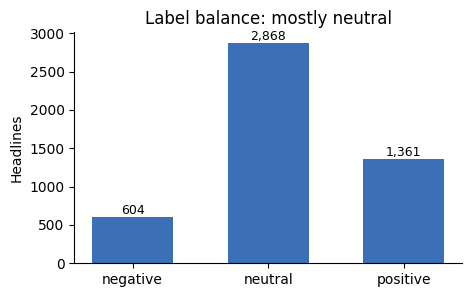

In [10]:
counts = df["sentiment"].value_counts().reindex(LABELS)
print((counts / counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color="#3b6fb6", width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Label balance: mostly neutral")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

            count  mean   std  min   25%   50%   75%   max
sentiment                                                 
negative    604.0  23.9   9.9  5.0  17.0  22.0  30.0  56.0
neutral    2868.0  22.1   9.8  2.0  15.0  21.0  28.0  81.0
positive   1361.0  24.7  10.1  5.0  17.0  23.0  31.0  57.0


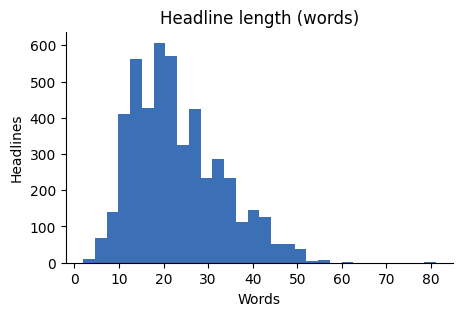

In [11]:
df["words"] = df["headline"].str.split().str.len()
print(df.groupby("sentiment")["words"].describe().round(1))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(df["words"], bins=30, color="#3b6fb6")
ax.set_title("Headline length (words)")
ax.set_xlabel("Words")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [12]:
# Fixed seed, stratified. Few-shot examples and the supervised baseline
# use only `train`; `test` is never shown to a model before scoring.
train, test = train_test(df, n=300)
test.to_csv("data/kaggle/test_sample.csv", index=False)
print("Train:", len(train), "| Test:", len(test))
test["sentiment"].value_counts()


Train: 4533 | Test: 300


,count
sentiment,
neutral,178
positive,84
negative,38


## A3. Classifier evaluation: keyword baseline vs LLM

The LLM classifier is scored on the fixed 300-headline held-out sample with
a sentiment-only prompt. The live news chain uses a longer prompt that also
asks for relevance, but the Kaggle headlines have no target company, so that
instruction would only add noise here. Because LLM output varies between
runs (about 2 points of accuracy at n = 300), the score is the mean of
three runs.

In [13]:
from src.chains.kaggle import keyword_baseline, score, to_articles
from src.chains.news_chain import (
    CLASSIFY_SENTIMENT_SYSTEM,
    classify,
    coverage,
)

METRICS = ("accuracy", "macro_f1")
N_RUNS = 3  # LLM output varies run to run; report the mean, not one draw

keyword_pred = list(test["headline"].map(keyword_baseline))
base = score(test["sentiment"], keyword_pred)
print("Keyword baseline:", {k: base[k] for k in METRICS})

articles = to_articles(test)
runs, zero_preds = [], []
for r in range(N_RUNS):
    labels = classify(articles, system=CLASSIFY_SENTIMENT_SYSTEM)
    missing = coverage(labels, articles)["missing_ids"]
    pred = [
        labels.get(i, {}).get("sentiment", "neutral")
        for i in range(len(test))
    ]
    zero_preds.append(pred)
    runs.append(score(test["sentiment"], pred))
    print(
        f"LLM run {r + 1}:",
        {k: runs[-1][k] for k in METRICS},
        f"| unlabeled: {len(missing)}",
    )

mean = {k: round(sum(s[k] for s in runs) / N_RUNS, 3) for k in METRICS}
print("LLM mean of", N_RUNS, "runs:", mean)

llm = runs[-1]  # last run's per-class report and confusion matrix
print(llm["report"])


Keyword baseline: {'accuracy': 0.687, 'macro_f1': 0.575}
LLM run 1: {'accuracy': 0.827, 'macro_f1': 0.831} | unlabeled: 0
LLM run 2: {'accuracy': 0.833, 'macro_f1': 0.841} | unlabeled: 0
LLM run 3: {'accuracy': 0.827, 'macro_f1': 0.839} | unlabeled: 0
LLM mean of 3 runs: {'accuracy': 0.829, 'macro_f1': 0.837}
              precision    recall  f1-score   support

    negative       0.90      1.00      0.95        38
     neutral       0.86      0.84      0.85       178
    positive       0.71      0.71      0.71        84

    accuracy                           0.83       300
   macro avg       0.83      0.85      0.84       300
weighted avg       0.83      0.83      0.83       300



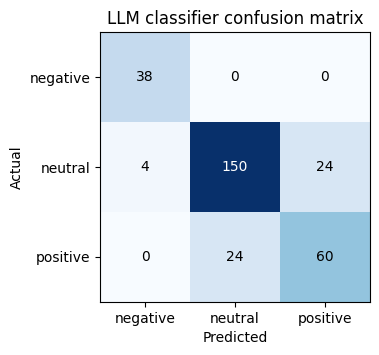

In [14]:
cm = llm["confusion"]

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)
ax.set_title("LLM classifier confusion matrix")
plt.show()

## A4. Classifier diagnostics: supervised baseline, few-shot prompts, agreement

Three checks on the zero-shot LLM classifier above:

1. **A supervised baseline.** A pretrained model can be applied to a task
   by prompting it or by training on labeled data (Jurafsky & Martin, 2026,
   Section 9.4). TF-IDF with logistic regression, trained on the same
   train split, stands in for the second, so the LLM is compared with a
   model that learned from these labels and not only with keywords.
2. **Few-shot prompting.** Two demonstrations per label are added to the
   prompt, drawn from the train split, as Brown et al. (2020, Section 2.4)
   draw conditioning examples from the training set and never from the
   test set. Demonstrations come from sentences every annotator agreed
   on, and K is fixed in advance rather than tuned on the test set. The
   sentiment definition in the prompt now restates the PhraseBank
   annotation guideline: judge only what the sentence states, from an
   investor's view of the stock price (Malo et al., 2014).
3. **Majority vote across runs.** The three runs per prompt are combined
   by majority vote, the self-consistency idea of keeping the answer most
   samples agree on (Wang et al., 2023). It reuses the runs already made,
   so it adds no API calls.

Finally, accuracy is broken down by annotator agreement. If the model is
far more accurate where every annotator agreed, many remaining "errors"
are sentences that people also labeled differently.


In [15]:
from src.chains.kaggle import (
    fewshot_examples,
    load_agreement,
    majority_vote,
    score_by_agreement,
    tfidf_baseline,
)

agreement = load_agreement()
print("Sentences with an agreement band:", len(agreement))

tfidf_pred = tfidf_baseline(train, test)

examples = fewshot_examples(train, per_label=2, agreement=agreement)
print("Few-shot demonstrations (train split, unanimous labels):")
for text, label in examples:
    print(f"  {label:>8}: {text[:90]}")

few_preds = []
for r in range(N_RUNS):
    labels = classify(
        articles, system=CLASSIFY_SENTIMENT_SYSTEM, examples=examples
    )
    few_preds.append(
        [
            labels.get(i, {}).get("sentiment", "neutral")
            for i in range(len(test))
        ]
    )

candidates = {
    "keyword": [keyword_pred],
    "tf-idf + logistic regression": [tfidf_pred],
    "LLM zero-shot": zero_preds,
    "LLM few-shot": few_preds,
}
rows = []
for name, preds in candidates.items():
    per_run = [score(test["sentiment"], p) for p in preds]
    vote = score(test["sentiment"], majority_vote(preds))
    rows.append(
        {
            "classifier": name,
            "runs": len(preds),
            **{
                f"{m} (mean)": round(
                    sum(s[m] for s in per_run) / len(preds), 3
                )
                for m in METRICS
            },
            **{f"{m} (vote)": vote[m] for m in METRICS},
        }
    )
comparison = pd.DataFrame(rows)
comparison


Sentences with an agreement band: 4835
Few-shot demonstrations (train split, unanimous labels):
  negative: The fair value of the company 's investment properties went down to EUR 2.768 billion at t
  negative: At 1411 CET , ArcelorMittal had lost 7.26 % to EUR 17.38 on Euronext Paris , coming at the
   neutral: Cramo Plc is a service company specialising in construction machinery and equipment rental
   neutral: The building will house product development and test laboratories .
  positive: Section : Regional News - The demand in Finnair 's Asian traffic , measured in passenger k
  positive: The Group also has a strong global position in other fishing categories .


,classifier,runs,accuracy (mean),macro_f1 (mean),accuracy (vote),macro_f1 (vote)
0,keyword,1,0.687,0.575,0.687,0.575
1,tf-idf + logistic regression,1,0.793,0.771,0.793,0.771
2,LLM zero-shot,3,0.829,0.837,0.827,0.840
3,LLM few-shot,3,0.835,0.841,0.837,0.848


Test sentences per band: {'100%': 149, '75-99%': 71, '66-74%': 42, '50-65%': 38}


classifier,LLM few-shot (vote),LLM zero-shot (vote),tf-idf + LR
band,,,
100%,0.960,0.940,0.899
75-99%,0.831,0.887,0.775
66-74%,0.762,0.667,0.762
50-65%,0.447,0.447,0.447


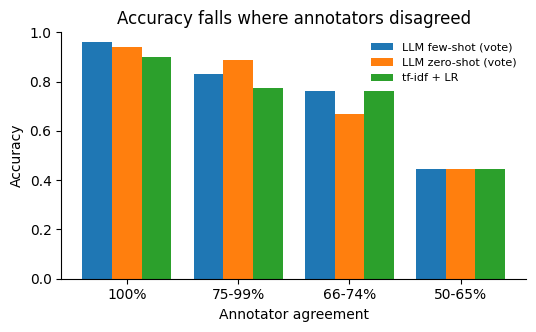

In [16]:
final_preds = {
    "tf-idf + LR": tfidf_pred,
    "LLM zero-shot (vote)": majority_vote(zero_preds),
    "LLM few-shot (vote)": majority_vote(few_preds),
}
by_band = pd.concat(
    score_by_agreement(test, p, agreement).assign(classifier=name)
    for name, p in final_preds.items()
)
band_order = ["100%", "75-99%", "66-74%", "50-65%"]
acc = by_band.pivot(index="band", columns="classifier", values="accuracy")
acc = acc.reindex([b for b in band_order if b in acc.index])
counts = by_band.drop_duplicates("band").set_index("band")["n"]
print("Test sentences per band:", counts.reindex(acc.index).to_dict())
display(acc)

fig, ax = plt.subplots(figsize=(6, 3.2))
width = 0.8 / len(acc.columns)
for j, name in enumerate(acc.columns):
    offset = (j - (len(acc.columns) - 1) / 2) * width
    xs = [i + offset for i in range(len(acc))]
    ax.bar(xs, acc[name], width, label=name)
ax.set_xticks(range(len(acc)), acc.index)
ax.set_xlabel("Annotator agreement")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Accuracy falls where annotators disagreed")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()


### Interpretation of A4: financial sentiment classification

On the 300-headline held-out test set, the **few-shot LLM majority vote**
recorded macro-F1 **0.848**, compared with **0.840** for zero-shot voting,
**0.771** for TF–IDF logistic regression, and **0.575** for the keyword
baseline. The small difference between the two LLM prompting conditions
should not be treated as statistically established. Accuracy also depends on
label consensus: few-shot accuracy was **96.0%** for unanimous headlines,
versus **44.7%** for the lowest agreement band (50–65%). This underscores
the difficulty of inherently ambiguous financial headlines and the limits
of evaluating on a public benchmark.


## A5. Interpretation of sentiment results

The computed comparison table above reports both the mean of repeated LLM
classifications and their majority-vote results. The next cell summarizes the
measured differences without assuming the same values will recur on another
run. Confusion matrices and annotator-agreement bands provide necessary
context: accuracy alone can hide class imbalance, and disagreement among
human annotators makes a headline classification intrinsically ambiguous.

The Financial PhraseBank is public and may overlap with model pretraining
data. Therefore these measurements describe performance on this particular
benchmark, **not verified generalization to unseen current news**. The
separate October 14 and October 18 exploratory runs used different processing
conditions and are not treated as a controlled causal comparison here.


In [17]:
# Directly summarize this notebook's current classification results.
metric_cols = ["classifier", "accuracy (mean)", "macro_f1 (mean)"]
display(comparison[metric_cols].sort_values("macro_f1 (mean)", ascending=False))

best = comparison.loc[comparison["macro_f1 (mean)"].idxmax()]
print("Highest observed macro-F1:", best["classifier"],
      "| score:", round(float(best["macro_f1 (mean)"]), 3))
print("Accuracy by agreement level is reported in the preceding table and plot.")


,classifier,accuracy (mean),macro_f1 (mean)
3,LLM few-shot,0.835,0.841
2,LLM zero-shot,0.829,0.837
1,tf-idf + logistic regression,0.793,0.771
0,keyword,0.687,0.575


Highest observed macro-F1: LLM few-shot | score: 0.841
Accuracy by agreement level is reported in the preceding table and plot.


# Part B. Autonomous research workflow

## Agent Design and Workflows

EquityAgent is implemented as a LangGraph state graph (`src/graph.py`). Each
research request passes through planning, specialist routing, data gathering,
synthesis, iterative evaluation and revision, reflection, and memory storage.
Specialists run independently and can be executed concurrently.

```text
Ticker → Plan → Route → Specialists → Synthesize → Evaluate
                                                 ↓       ↑
                                              Refine → Optimize
                                                 |
                                            Final selection
                                                 ↓
                                          Reflect → Memory
```

| Stage | Implementation | Evidence shown |
|---|---|---|
| Planning and routing | `src/agents/planner.py`, `router.py` | Plan and routing decisions |
| Retrieval and specialists | `src/agents/specialists.py`, `src/tools/` | Tool trace and retrieved findings |
| News NLP | `src/chains/news_chain.py` | Chained classification and news summary |
| Report generation | `src/agents/synthesizer.py` | Research brief |
| Evaluation and revision | `src/agents/evaluator.py`, `evaluation_pipeline.py` | Rubric scores, critiques, numeric audit |
| Reflection and memory | `src/memory/store.py` | Lessons written and reused |

The first demonstration uses NVDA and begins with empty **experiment-local**
agent memory. A subsequent run tests whether previously stored lessons alter
the planning process. Clearing the notes file is intentional for this
controlled local experiment and does not change files in the source repository.


## B1. Setup check: every tool returns data


In [18]:
print("Chunks indexed:", index_filings(TICKERS))
pd.DataFrame({t: quick_smoke(t) for t in TICKERS})

Chunks indexed: 566


,NVDA,JPM,XOM
get_price_history,ok,ok,ok
get_key_stats,ok,ok,ok
get_financials,ok,ok,ok
get_macro_snapshot,ok,ok,ok
get_news,ok,ok,ok


## B2. Research plan

The planner reads memory first. On the first run of a ticker there are no
notes; later runs show the lessons it used.

In [19]:
# Start from empty memory so the first run below is a true first run.
store.NOTES_PATH.unlink(missing_ok=True)
print("Lessons in memory:", len(store.load_notes()))


Lessons in memory: 0


In [21]:
TICKER = "NVDA"
notes_before = store.load_notes()

report, trace, state = run_agent(TICKER, reviewed_evaluation=True)

print("Sector:", state["sector"])
print("Hypothesis:", state["plan"].hypothesis)
show.plan_table(trace)

Sector: Technology
Hypothesis: Can Nvidia sustain its premium valuation given AI-driven demand growth amid rising competition, supply constraints, and macro headwinds?


,id,task,tool,purpose,priority
0,1,"Retrieve key statistics including market cap, P/E, margins, ROE, and analyst price targets",get_key_stats,Establish current valuation and profitability benchmarks to assess if premium pricing is justified,high
1,2,"Analyze annual income statement, balance sheet, and cash flow trends",get_financials,"Evaluate revenue growth trajectory, margin expansion, R&D spend, and balance sheet strength to support growth thesis",high
2,3,"Pull 5-year daily price history to compute volatility, returns, and beta vs SPY",get_price_history,Understand historical risk-adjusted returns and market sensitivity given stock's high volatility profile,high
3,4,Fetch recent news headlines from the last 30 days,get_news,"Capture latest developments on AI chip demand, competitive dynamics, export restrictions, and product launches",high
4,5,"Get macro snapshot including CPI, Fed funds rate, 10-year yield, and GDP trends",get_macro_snapshot,Assess how interest rate environment and economic conditions may impact capex spending on AI infrastructure and grow...,medium
5,6,"Search latest 10-K for risk factors related to export controls, China exposure, and supply chain concentration",search_filings,Identify geopolitical and regulatory risks given Nvidia's dependence on TSMC and exposure to US-China trade restrict...,high
6,7,Search 10-K MD&A for commentary on competitive landscape and customer concentration,search_filings,"Evaluate risks from hyperscaler customers developing in-house chips and competitive threats from AMD, Intel, and cus...",medium


In [22]:
show.memory_read(trace)

No prior lessons: first run for this ticker and sector.


,lesson


## B3. Tool calls (dynamic tool use)

The plan, not the code, decides which tools run and with what query.
The three specialists run in parallel, so the log is grouped by the
specialist (`route`) that made each call.


In [23]:
show.tool_log(trace)

,route,tool,args,ok,rows,error
0,earnings,get_key_stats,{},True,14,None
1,earnings,get_financials,{},True,12,None
2,earnings,search_filings,"{'query': 'Search latest 10-K for risk factors related to export controls, China exposure, and supply chain concentr...",True,3,None
3,earnings,search_filings,{'query': 'Search 10-K MD&A for commentary on competitive landscape and customer concentration'},True,3,None
4,market,get_price_history,{},True,7,None
5,market,get_macro_snapshot,{},True,5,None
6,news,get_news,{},True,99,None


## B4. Routing decisions

In [24]:
show.routing_table(trace)

,step_id,route,reason
0,1,earnings,"The task focuses on valuation and profitability metrics, including P/E, margins, and ROE, alongside analyst price ta..."
1,2,earnings,"This task analyzes annual financial statements, growth and margin trends, R&D spending, and balance sheet strength."
2,3,market,"This task analyzes five-year daily price history to calculate volatility, returns, and beta versus SPY."
3,4,news,"The task requests recent headlines on developments over the last 30 days, including AI chip demand, competition, exp..."
4,5,market,The task requests macroeconomic indicators and interest-rate context that can affect AI infrastructure capex and gro...
5,6,earnings,"This task requires searching Nvidia’s latest 10-K risk-factor disclosures about export controls, China exposure, and..."
6,7,earnings,This task requires searching 10-K MD&A for competitive risks and customer concentration disclosures.


## B5. News prompt chain: output of each step

The digest's `net_sentiment` is not the model's opinion: the chain counts
the per-article labels from the classify step and applies majority rule
with a 15-point margin (`sentiment_counts` is printed with the summary).
Empty `figures` lists in the extract step are expected for headline-only
items; the extractor only reports numbers that appear in the text.


In [25]:
show.news_chain_steps(trace)


=== INGEST ===
{
 "n": 99,
 "sample": [
  "Nvidia says its new AI safety platform can contain rogue agents within \u2018milliseconds\u2019",
  "Nvidia launches agent safety platform backed by over 100 companies",
  "Nvidia commits $250M of compute to UK AI safety research",
  "Nvidia-backed Reflection unveils Beam, its first open-weight model",
  "Nvidia adds a record $150bn to its share buyback"
 ],
 "earliest": "2026-09-19T10:32:00Z",
 "latest": "2026-10-17T14:38:18Z"
}

=== PREPROCESS ===
{
 "n_in": 99,
 "n_out": 98,
 "duplicate": 0,
 "non_news": 1,
 "stale": 0,
 "no_mention": 0
}

=== CLASSIFY ===
{
 "0": {
  "id": 0,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "1": {
  "id": 1,
  "topic": "product",
  "sentiment": "positive",
  "relevance": "high"
 },
 "2": {
  "id": 2,
  "topic": "other",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "3": {
  "id": 3,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "4": {
  "id": 4

## B6. Specialist findings

In [26]:
show.findings_table(trace)

,route,summary,key_figures,risks
0,market,"NVDA closed at $214.13, down 2.38% over the past month but up 19.07% over the past year, with annualized volatility ...","[Last close: $214.13, 1-month return: -2.38%, 1-year return: 19.07%, Annualized volatility: 37.27%, 50-day SMA: $223...","[High beta (2.128) means NVDA moves roughly twice as much as the broader market, increasing downside risk in a sello..."
1,earnings,"NVDA's FY2026 (ended 1/31/2026) revenue reached $215.9B, up 65.5% YoY from $130.5B in FY2025, with operating income ...","[Market Cap: $5,170,596,937,728, Trailing P/E: 27.07, Forward P/E: 13.45, Price/Book: 22.58, Profit Margin (TTM): 63...","[Export controls: 'Export controls have and could in the future disrupt our supply chain and distribution channels, ..."
2,news,"Sentiment is neutral, consistent with the 58 neutral items outweighing 25 positive and 13 negative. The large buybac...","[Nvidia authorized an additional $150 billion in share repurchases, bringing remaining authorization to $235 billion...","[An analyst commentary warned that a substantial amount of Nvidia revenue could be sitting in warehouses, raising co..."


## B7. Evaluator–Optimizer: generate, evaluate, and refine

The research agent synthesizes an initial brief, scores five criteria from
1 to 5 (**completeness, evidence, accuracy, balance, and clarity**), then
uses specific evaluation feedback to revise the brief. Claude Sonnet 5 writes
and optimizes the drafts; GPT-6 Sol evaluates them. These are distinct model
roles, rather than two independent scoring models.

The **baseline acceptance policy** requires an average of at least 4.0 after
the minimum revision count. The **enhanced quality policy** additionally
requires accuracy and evidence scores of at least 4/5, blocks acceptance on
recognized numerical contradictions, records unresolved figures, and can
select the highest scoring acceptable revision.

| Acceptance rule | Baseline | Enhanced policy |
|---|---|---|
| Minimum average | 4.0 | 4.0 |
| Minimum accuracy | No separate floor | 4 / 5 |
| Minimum evidence | No separate floor | 4 / 5 |
| Minimum revision rounds | 1 | 1 |
| Maximum evaluated drafts | 3 | 3 |
| Contradictions found by limited numeric parser | Not a separate gate | Block acceptance |
| Final draft choice | Last evaluated revision | Best accepted revision |

Unrecognized or unsupported claims are **unverified**, not proven correct.
The parser covers only a narrow subset of financial prose; discrepancies
require human review. Exhausting the evaluation budget does not constitute
acceptance.


In [27]:
show.evaluation_history(state)

,iteration,average,completeness,evidence,accuracy,balance,clarity
0,0,4.0,5,3,3,5,4
1,1,4.6,5,4,5,5,4
2,2,4.0,4,4,5,4,3


In [28]:
show.critiques(state)


Iteration 0 (avg 4.0):
  - Correct the buyback description: $235B is the remaining repurchase authorization, not the total authorized; authorization does not mean $150B of purchases has been funded or made.
  - Do not present SpaceX’s reported $40B financing effort as a chip order or a confirmed demand pipeline. The finding says the prospective transaction is unconfirmed.
  - Replace “100+ organizations” adopting the safety platform with “more than 100 participating organizations” or “broad industry backing”; adoption is not established.
  - Qualify the conclusion that inventory risks are “not yet reflected in demand signals.” The findings include an inventory warning, while analyst consensus is not itself evidence of realized demand.
  - Remove or substantiate “accelerating” growth, “industry-leading” margins, and “channel stuffing”; the findings do not establish those comparisons or that allegation.
  - Make the portfolio action more precise: the brief calls NVDA a high-conviction l

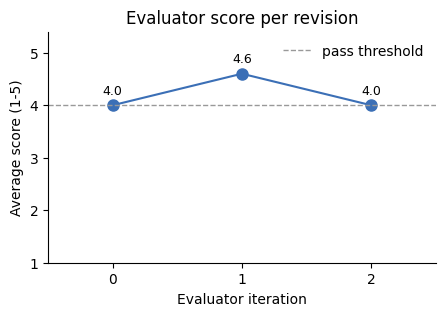

In [29]:
show.plot_scores(state)
plt.show()

In [30]:
# Summarize live rubric decisions and numeric audit coverage.
review_rows = []
for item in state["history"]:
    scores = item["scores"]
    review_rows.append({
        "iteration": item["iteration"],
        "average": item["average"],
        "accuracy": scores["accuracy"],
        "evidence": scores["evidence"],
        "passed": item.get("accepted", False),
        "selected": item.get("selected", False),
        "reason": ", ".join(item.get("failures", [])) or "none",
        "numeric_checked": item.get("numeric_checked", 0),
        "numeric_unverified": item.get("numeric_unverified", 0),
        "numeric_contradicted": item.get("numeric_contradicted", 0),
    })
review_df = pd.DataFrame(review_rows)
display(review_df[["iteration", "average", "accuracy", "evidence",
                   "passed", "selected", "reason"]])
display(review_df[["iteration", "numeric_checked", "numeric_unverified",
                   "numeric_contradicted"]])

print("Final decision:", "accepted" if state["accepted"] else "not accepted")
print("Selected revision:", state["selected_iteration"])
print("Selected rubric average:", state["evaluation"].average)
print("Numeric claims checked:", len(state["numeric_audit"].checks))

numeric_rows = state["numeric_audit"].rows()
if numeric_rows:
    display(pd.DataFrame(numeric_rows))
else:
    print("No claims matched the constrained numeric validator.")


,iteration,average,accuracy,evidence,passed,selected,reason
0,0,4.0,3,3,False,False,"accuracy_below_threshold, evidence_below_threshold"
1,1,4.6,5,4,False,False,numeric_contradictions
2,2,4.0,5,4,True,True,none


,iteration,numeric_checked,numeric_unverified,numeric_contradicted
0,0,2,2,0
1,1,5,3,1
2,2,3,2,0


Final decision: accepted
Selected revision: 2
Selected rubric average: 4.0
Numeric claims checked: 3


,kind,status,metric,period,observed,expected,reason,excerpt
0,reported,unverified,revenue,None,215900000000.0,None,no_comparable_metric_period_unit_in_findings,revenue of $215.9B
1,reported,supported,net income,None,120100000000.0,120100000000.0,matching_metric_period_and_value,net income of $120.1B
2,reported,unverified,free cash flow,None,96700000000.0,None,no_comparable_metric_period_unit_in_findings,free cash flow was $96.7B


### Interpretation of B7: evaluation and iterative revision

The first NVDA draft scored **4.0/5**, but its **accuracy and evidence scores
were each 3/5**, below the explicit quality thresholds. The next draft scored
**4.6/5**, yet a recognized numerical contradiction prevented acceptance.
Following another revision, the accepted draft scored **4.0/5** with no
contradictions among **three recognized numerical checks**. Two of those
checks remained **unverified**, so zero detected contradictions must not be
interpreted as comprehensive financial fact checking. The final selected
draft scored lower on the LLM rubric than the preceding candidate because
the policy gives verified contradictions precedence over the average score.


## B8. Final report

In [31]:
if not state["accepted"]:
    print("Quality criteria were not met; the following report is retained for diagnostic review.")
display(show.report_markdown(report))


# NVDA research brief

**Thesis:** NVDA grew FY2026 revenue 65.5% YoY to \$215.9B (\$215,938M) with 55.6% net margin and \$96.7B (\$96,676M) free cash flow, supporting a \$150B incremental buyback that lifts total remaining authorization to \$235B. Valuation is rich (27.1x trailing P/E, 22.6x P/B) and shares sit below the 50-day SMA amid a sharp rise in the 10-year yield (to 5.10%) and high beta (2.13). Export-control and inventory risks remain unresolved. We view NVDA as a long-term hold, favoring adds nearer the 200-day SMA (~\$203) over chasing strength.

## Bull case
- FY2026 revenue grew 65.5% YoY to \$215.9B (\$215,938M) with 60.4% operating margin and 55.6% net margin
- Free cash flow reached \$96.7B (\$96,676M), up from \$60.9B in FY2025, on a low-leverage balance sheet (0.07x debt-to-equity), supporting a \$150B incremental buyback authorization that brings total remaining repurchase capacity to \$235B
- ROE of 117.2% and a forward P/E of 13.5x (vs 27.1x trailing) imply the market expects continued strong earnings growth
- Nvidia's Open Agent Safety Platform drew broad industry backing (reported 100+ participating organizations), reinforcing its ecosystem position beyond hardware
- Strong-buy consensus from 59 analysts (mean target \$328.72) reflects confidence, alongside reports of large prospective chip purchases such as SpaceX's \$40B financing effort, though unconfirmed

## Bear case
- Stock trades below its 50-day SMA (\$223.08 vs \$214.13 close) with high beta (2.13) and 37.3% annualized volatility, amplifying downside risk in a market pullback
- 10-year Treasury yield surged to 5.10% (up ~100bps YoY), a headwind for high-multiple growth stocks via higher discount rates
- Export-control and China-related geopolitical risk are explicit and recurring, including an unresolved allegation by U.S. authorities that a California man smuggled about \$300M in Nvidia chips to China, and prior H20-related inventory disruption
- Analyst commentary has raised concerns that a substantial amount of Nvidia revenue could be sitting in channel inventory, though the findings do not establish its ownership or sell-through status
- Customer concentration and third-party supply-chain dependency remain structural vulnerabilities; reported RTX 5090 shortages point to supply/product-mix uncertainty

## Fundamentals
NVDA's FY2026 results show revenue of \$215.9B (\$215,938M), up 65.5% YoY from \$130.5B, with operating income of \$130.4B (60.4% margin, down slightly from 62.4% in FY2025) and net income of \$120.1B (55.6% margin). Diluted EPS rose to \$4.90 from \$2.94. The balance sheet is conservative, with \$11.0B total debt against \$157.3B equity (0.07x debt-to-equity) and \$10.6B cash. Operating cash flow was \$102.7B and free cash flow was \$96.7B (\$96,676M), up from \$60.9B in FY2025. Valuation is elevated at 27.1x trailing P/E and 22.6x price-to-book, though the 13.5x forward P/E implies embedded growth expectations; market cap is \$5.17T, with a strong-buy consensus (mean target \$328.72, 59 analysts).

## News and catalysts
Sentiment is net neutral (58 neutral, 25 positive, 13 negative items). Positive catalysts include an additional \$150B buyback authorization, which brought total remaining repurchase capacity to \$235B; broad industry backing for the Open Agent Safety Platform (reported 100+ participating organizations); a record share price since May; and reports of large prospective chip purchases—including SpaceX's reported \$40B financing effort—though that transaction remains unconfirmed. Offsetting these are analyst commentary warning that a substantial amount of revenue could be sitting in channel inventory (status unconfirmed), a high-severity GPU monitoring vulnerability, RTX 5090 supply shortages, and a high-profile case in which U.S. authorities allege a California man smuggled about \$300M in Nvidia chips to China.

## Market and macro
NVDA closed at \$214.13, down 2.38% over the past month but up 19.07% over the past year, trading below its 50-day SMA (\$223.08) yet above its 200-day SMA (\$202.97), suggesting a near-term pullback within a longer-term uptrend. High beta (2.128) and annualized volatility of 37.27% indicate amplified sensitivity to market swings. Macro conditions are mixed: the Fed funds rate eased to 3.75%, unemployment ticked down to 4.2%, and real GDP grew 2.19% YoY, but CPI remains elevated at 3.72% YoY and the 10-year Treasury yield jumped sharply to 5.10%, a headwind for high-multiple growth equities like NVDA.

## Conclusion
NVDA's underlying business remains strong—high growth, high margins, robust cash generation, and low leverage support an expanded buyback authorization—but valuation is rich on trailing multiples and shares are exposed to rising long-term yields and high beta. Inventory and export-control risks are real but unresolved, and the strong-buy analyst consensus reflects sentiment rather than confirmed demand. We treat NVDA as a long-term hold: a disciplined investor might add near the 200-day SMA (~\$203) as a lower-risk entry point, and treat trading near or above the 50-day SMA (~\$223) as a volatility-based signal to pause new buying—given the stock's elevated beta and swings—rather than a fundamental sell trigger. This is not investment advice.

*Analysis only; not investment advice.*

## B9. Reflection (self-assessment of output and process)

In [32]:
show.reflection_view(state)

{'weakest_section': 'Bull case',
 'unsupported_claims': ["SpaceX's $40B financing effort for chip purchases is repeated in bull case as a demand signal despite being explicitly unconfirmed",
  '100+ organizations backing Open Agent Safety Platform is based on a single report and presented as established fact',
  "Strong-buy analyst consensus is framed as reflecting 'confidence' without noting potential herd bias or lag in analyst targets relative to price moves",
  'Channel inventory concern is mentioned but its magnitude/materiality is never quantified despite being a recurring bear point'],
 'missing_data': ['No breakdown of revenue by segment (data center vs gaming vs automotive) to assess concentration risk quantitatively',
  'No specific disclosure of customer concentration percentages (e.g., % revenue from top 1-2 customers)',
  'No forward guidance figures from management (next quarter/FY revenue or margin guidance)',
  "No comparison to peer multiples (AMD, AVGO, or semiconduct

## B10. Memory: what this run taught the agent

New lessons written to `memory/notes.json`, then a second run on the same
ticker to show the planner reading them.

In [33]:
show.memory_diff(trace)

,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-19,"For high-growth tech/semis, always pull segment revenue and customer concentration data from filings to quantify sta..."
1,NVDA,Technology,2026-10-19,"When citing forward P/E as evidence of embedded growth expectations, pull actual consensus revenue/EPS growth estima..."
2,NVDA,Technology,2026-10-19,"Treat single-source, unconfirmed news items (e.g., large customer financing deals) as explicitly speculative in both..."
3,NVDA,Technology,2026-10-19,"For richly-valued, high-beta names, include a peer or sector multiple comparison to give valuation claims a benchmark"
4,NVDA,Technology,2026-10-19,"When macro rates (10Y yield) are cited as a headwind, quantify the duration/sensitivity impact (e.g., approximate mu..."


In [34]:
report2, trace2, state2 = run_agent(TICKER, reviewed_evaluation=True)
print("Lessons the planner read on run 2:")
display(show.memory_read(trace2))
print("Run 1 steps:", [s.tool for s in state["plan"].steps])
print("Run 2 steps:", [s.tool for s in state2["plan"].steps])
print("Run 1 final score:", state["evaluation"].average,
      "| Run 2 final score:", state2["evaluation"].average)

Lessons the planner read on run 2:


,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-19,"For high-growth tech/semis, always pull segment revenue and customer concentration data from filings to quantify sta..."
1,NVDA,Technology,2026-10-19,"When citing forward P/E as evidence of embedded growth expectations, pull actual consensus revenue/EPS growth estima..."
2,NVDA,Technology,2026-10-19,"Treat single-source, unconfirmed news items (e.g., large customer financing deals) as explicitly speculative in both..."
3,NVDA,Technology,2026-10-19,"For richly-valued, high-beta names, include a peer or sector multiple comparison to give valuation claims a benchmark"
4,NVDA,Technology,2026-10-19,"When macro rates (10Y yield) are cited as a headwind, quantify the duration/sensitivity impact (e.g., approximate mu..."


Run 1 steps: ['get_key_stats', 'get_financials', 'get_price_history', 'get_news', 'get_macro_snapshot', 'search_filings', 'search_filings']
Run 2 steps: ['get_key_stats', 'get_financials', 'search_filings', 'search_filings', 'get_price_history', 'get_macro_snapshot', 'get_news', 'get_key_stats']
Run 1 final score: 4.0 | Run 2 final score: 4.6


# Part C. Evaluation and comparative analysis

## Evaluation and Iteration

The following experiments assess different aspects of the system, with
limitations appropriate to each comparison. The no-tools baseline examines
the value of access to research findings and the overall agent workflow; it
does **not isolate the revision loop**. The memory comparison uses separate
live agent runs and therefore cannot isolate the causal effect of memory from
model and data variation. The policy replay applies original and enhanced
acceptance criteria to the **same sequence of observed rubric scores**.

An LLM rubric supplies qualitative scores throughout. Numeric spot-checks
are constrained by the parser and the formats of retrieved specialist data.


## C1. Report quality, numerical evidence, and memory

Three descriptive analyses are reported:

1. **No-tools versus research agent.** For each ticker, the baseline
   produces a brief without the specialist findings. Both briefs are graded
   against the same collected findings. This measures the combined effect of
   research evidence and agent workflow, not one component in isolation.
2. **Unsupported figure counts.** A string-based check flags figures not
   repeated verbatim in findings. Rounding, scaling, and unit formatting can
   produce false positives; this measure is a review aid, not fact checking.
3. **Memory on versus off.** Plans and rubric scores are compared across
   separate runs. Variation from LLM outputs and data availability remains
   a confounder.

The complete ticker comparison is also saved as a CSV to facilitate the
accompanying written report. The computed table, rather than any earlier
exploratory scores, is the source for the reported results.


In [35]:
rows = []
for t in TICKERS:
    rep, tr, st = run_agent(t, reviewed_evaluation=True)
    base = baseline_brief(t)
    base_score = score_against_findings(base, st["findings"])
    findings = st["findings"]
    rows.append(
        {
            "ticker": t,
            "baseline_avg": base_score["average"],
            "agent_first_draft": st["history"][0]["average"],
            "agent_final": st["evaluation"].average,
            "accepted": st["accepted"],
            "selected_iteration": st["selected_iteration"],
            "numeric_checked": len(st["numeric_audit"].checks),
            "numeric_contradicted": len(st["numeric_audit"].contradictions),
            "numeric_unverified": len(st["numeric_audit"].unverified),
            "iterations": len(st["history"]),
            "tool_success": tool_success_rate(tr),
            "unsupported_baseline": len(unsupported_figures(base, findings)),
            "unsupported_agent": len(
                unsupported_figures(st["draft"], findings)
            ),
        }
    )
results = pd.DataFrame(rows)
display(results[["ticker", "baseline_avg", "agent_first_draft",
                 "agent_final", "accepted", "selected_iteration"]])
display(results[["ticker", "numeric_checked", "numeric_contradicted",
                 "numeric_unverified", "unsupported_baseline",
                 "unsupported_agent", "tool_success"]])


,ticker,baseline_avg,agent_first_draft,agent_final,accepted,selected_iteration
0,NVDA,1.8,4.2,4.4,True,1
1,JPM,2.0,4.4,4.4,True,1
2,XOM,1.6,4.4,4.4,True,0


,ticker,numeric_checked,numeric_contradicted,numeric_unverified,unsupported_baseline,unsupported_agent,tool_success
0,NVDA,4,0,2,4,5,1.0
1,JPM,1,0,0,8,8,1.0
2,XOM,0,0,0,14,12,1.0


In [36]:
from pathlib import Path
table1_path = Path("Results/table1_integrated_live_run.csv")
table1_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(table1_path, index=False)
print("Table 1 saved:", table1_path.resolve())
print(results.to_string(index=False))


Table 1 saved: /content/drive/MyDrive/equity-agent-pawan-integration-review/Results/table1_integrated_live_run.csv
ticker  baseline_avg  agent_first_draft  agent_final  accepted  selected_iteration  numeric_checked  numeric_contradicted  numeric_unverified  iterations  tool_success  unsupported_baseline  unsupported_agent
  NVDA           1.8                4.2          4.4      True                   1                4                     0                   2           2           1.0                     4                  5
   JPM           2.0                4.4          4.4      True                   1                1                     0                   0           2           1.0                     8                  8
   XOM           1.6                4.4          4.4      True                   0                0                     0                   0           2           1.0                    14                 12


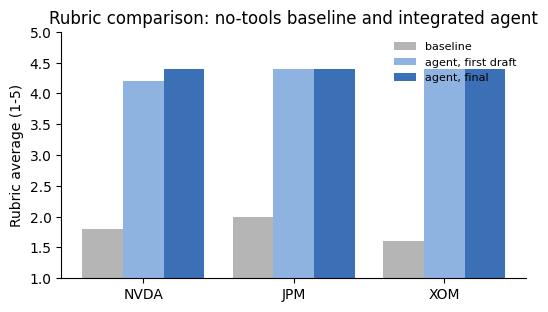

In [37]:
fig, ax = plt.subplots(figsize=(6, 3.2))
x = list(range(len(results)))
w = 0.27
series = [
    ("baseline_avg", "baseline", "#b5b5b5", -w),
    ("agent_first_draft", "agent, first draft", "#8fb3e0", 0),
    ("agent_final", "agent, final", "#3b6fb6", w),
]
for col, label, color, offset in series:
    ax.bar([i + offset for i in x], results[col], w, label=label, color=color)
ax.set_xticks(x, results["ticker"])
ax.set_ylim(1, 5)
ax.set_ylabel("Rubric average (1-5)")
ax.set_title("Rubric comparison: no-tools baseline and integrated agent")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [38]:
_, tr_off, st_off = run_agent(TICKER, use_memory=False, reviewed_evaluation=True)
_, tr_on, st_on = run_agent(TICKER, use_memory=True, reviewed_evaluation=True)
pd.DataFrame([
    {"memory": "off", "plan_steps": len(st_off["plan"].steps),
     "notes_read": len(tr_off.select("memory", "read")[0].output),
     "final_score": st_off["evaluation"].average},
    {"memory": "on", "plan_steps": len(st_on["plan"].steps),
     "notes_read": len(tr_on.select("memory", "read")[0].output),
     "final_score": st_on["evaluation"].average},
])

,memory,plan_steps,notes_read,final_score
0,off,7,0,4.4
1,on,8,8,4.2


In [39]:
show.timing_table(trace)

,seconds
step,
evaluator,20.7
optimizer,71.8
planner,9.3
reflection,12.4
router,14.2
specialist,75.6
specialists,53.8
synthesizer,17.7


### Interpretation of C1: comparative research and memory results

In the separate comparison runs for **NVDA, JPM, and XOM**, the no-tools
baselines scored **1.8, 2.0, and 1.6**, respectively; the research agent's
final drafts each scored **4.4/5**. This is evidence of better *rubric scores*
when specialists have access to retrieved findings, not independent proof of
financial accuracy. The tool success rate reported for these runs was
**100%**. The XOM evaluation selected iteration **0** despite evaluating two
drafts, illustrating the ability to retain an earlier preferred candidate.

In the memory ablation, the memory-off plan had **7 steps** and read
**0 lessons**; the memory-on plan had **8 steps** and read **8 lessons**.
Their final scores were **4.4** and **4.2**, respectively. This demonstrates
that stored lessons influenced planning, but does not establish a quality
improvement. The numeric parser examined only **4, 1, and 0** claims in the
three accepted research briefs, respectively, so financial coverage remains
limited. The exact-string unsupported-figure measure can also count benign
rounding or unit differences.


## C2. Paired Evaluator–Optimizer acceptance analysis

This is a controlled **decision-policy ablation** using the exact same
recorded NVDA drafts and LLM rubric scores. Both acceptance rules rely on
the same GPT-6 Sol evaluator, while Claude Sonnet 5 is responsible for draft
creation and revision. The exercise compares stopping decisions; it is not
a second independent live run or an experiment with a newly trained judge.

The baseline policy requires at least one revision and average score 4.0 or
higher. The enhanced policy adds separate evidence and accuracy thresholds,
a contradiction gate for recognizable financial claims, and retention of an
acceptable earlier draft when a subsequent revision is worse. Changes in
acceptance logic alone should not be interpreted as validated gains in
financial correctness or investment performance.


In [40]:
# Compare baseline and enhanced decisions on the same scored drafts.
# This is a policy replay, not another independent model evaluation.
from src.agents import evaluator as original_eval

original_stopped = False
replay_rows = []
for index, item in enumerate(state["history"]):
    iteration = item["iteration"]
    avg = item["average"]
    if original_stopped:
        original_action = "not reached"
    else:
        original_pass = (iteration >= original_eval.MIN_ITERATIONS
                         and avg >= original_eval.PASS_THRESHOLD)
        original_budget = iteration + 1 >= original_eval.MAX_ITERATIONS
        original_action = ("accept" if original_pass else
                           "exhausted" if original_budget else "revise")
        original_stopped = original_action != "revise"

    # Action the reviewed graph ACTUALLY took at the time of this row.
    last = index == len(state["history"]) - 1
    reviewed_action = ("revise" if not last else
                       "accept" if state["accepted"] else "exhausted")
    replay_rows.append({
        "iteration": iteration,
        "rubric_average": avg,
        "accuracy": item["scores"]["accuracy"],
        "evidence": item["scores"]["evidence"],
        "original_policy": original_action,
        "reviewed_policy": reviewed_action,
        "reviewed_failures": ", ".join(item.get("failures", [])) or "none",
    })
replay = pd.DataFrame(replay_rows)
display(replay)
print("Reviewed selected iteration:", state["selected_iteration"])
print("Original policy and reviewed policy use the same rubric scores.")


,iteration,rubric_average,accuracy,evidence,original_policy,reviewed_policy,reviewed_failures
0,0,4.0,3,3,revise,revise,"accuracy_below_threshold, evidence_below_threshold"
1,1,4.6,5,4,accept,revise,numeric_contradictions
2,2,4.0,5,4,not reached,accept,none


Reviewed selected iteration: 2
Original policy and reviewed policy use the same rubric scores.


### Interpretation of C2: matched evaluator policy comparison

The comparison uses the **same observed NVDA draft sequence and LLM scores**,
not two independently generated reports. Under the baseline stopping policy,
iteration **1** would be accepted with a **4.6/5** average. The enhanced
policy instead rejected iteration 1 because of a recognized numeric
contradiction and accepted iteration **2** at **4.0/5** after that detected
contradiction was removed. This illustrates how the two acceptance rules
differ; it does **not** demonstrate that one produces generally superior
investment recommendations. The enhanced policy's choice should also be
interpreted alongside the two unverified figures in its final numeric audit.


## C3. Limitations and threats to validity

- **Data provenance and currency.** Market prices, news, filings, and macro
  series come from external APIs or caches and may vary by run date. Published
  financial statements and the agent's retrieved excerpts should be
  cross-checked before investment use.
- **Judgment variability.** Rubric scores come from an LLM and can change
  between runs. Repeated evaluations and human ratings would be needed to
  estimate scoring reliability.
- **Numeric coverage.** Only a subset of explicitly formatted financial
  claims is recognized. A zero-contradiction audit is not a claim that all
  figures are correct. Missing, ambiguous, or conflicting source evidence
  remains unresolved.
- **Comparison scope.** The no-tools baseline differs in available evidence;
  the policy ablation shares observed scores; the memory comparison involves
  separate LLM runs. These answer different questions and should not be
  combined into one causal conclusion.
- **Benchmark leakage.** A publicly available sentiment dataset may have
  appeared in model pretraining. PhraseBank accuracy does not establish
  robustness across current market news, languages, or evolving companies.
- **Application scope.** Generated briefs are research aids, not verified
  investment recommendations. Human source review remains necessary.


## Discussion and conclusion

EquityAgent demonstrates an end-to-end architecture connecting financial data
retrieval, sentiment NLP, specialist research, structured synthesis, iterative
assessment, and memory. Part A evaluates language understanding against
baseline classifiers. Part B exposes each computational step and the evidence
supporting the final report. Part C distinguishes descriptive model scores,
source-grounding checks, and evaluator policy decisions.

The system combines a common five-criterion rubric with explicit
quality thresholds, selective financial-claim checks, revision
feedback, and selection of the strongest qualifying draft.
These controls improve auditability; broader claims of financial
accuracy require independent validation over more companies.

### Reproducibility and implementation

Source code, datasets, tests, and notebook construction are maintained in the
[project repository](https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final).
The setup cell records the checked-out commit. Model results, table values,
and figures are calculated by the code cells during execution, with API
responses and retrieval dates affecting reproducibility. Secrets are loaded
from Colab's credential store and are not embedded in the notebook.

**AI assistance disclosure:** ChatGPT assisted with code
development, debugging, test design, and technical writing,
particularly for the evaluation framework. The team reviewed
and tested the submitted implementation and reports the
measured notebook results separately from illustrative tests.

### References

- Brown, T. B., et al. (2020). *Language models are few-shot learners.*
  Advances in Neural Information Processing Systems, 33, 1877–1901.
  https://arxiv.org/abs/2005.14165
- Jurafsky, D., & Martin, J. H. (n.d.). *Speech and language processing*
  (3rd ed. draft). https://web.stanford.edu/~jurafsky/slp3/
- Lewis, P., et al. (2020). *Retrieval-augmented generation for
  knowledge-intensive NLP tasks.* Advances in Neural Information Processing
  Systems, 33. https://arxiv.org/abs/2005.11401
- Madaan, A., et al. (2023). *Self-refine: Iterative refinement with
  self-feedback.* Advances in Neural Information Processing Systems, 36.
  https://arxiv.org/abs/2303.17651
- Malo, P., Sinha, A., Korhonen, P., Wallenius, J., & Takala, P. (2014).
  Good debt or bad debt: Detecting semantic orientations in economic texts.
  *Journal of the Association for Information Science and Technology, 65*(4),
  782–796. https://doi.org/10.1002/asi.23062
- Shinn, N., Cassano, F., Gopinath, A., Narasimhan, K., & Yao, S. (2023).
  *Reflexion: Language agents with verbal reinforcement learning.* Advances
  in Neural Information Processing Systems, 36.
  https://arxiv.org/abs/2303.11366
- Wang, X., et al. (2023). *Self-consistency improves chain of thought
  reasoning in language models.* International Conference on Learning
  Representations. https://arxiv.org/abs/2203.11171
- Yao, S., et al. (2023). *ReAct: Synergizing reasoning and acting in language
  models.* International Conference on Learning Representations.
  https://arxiv.org/abs/2210.03629
